# Stroke Prevention using Machine Learning Techniques

## 1. Introduction

Stroke is a serious health condition that can lead to long-term disability or death, making early identification of individuals at risk important. Identifying potential stroke cases using demographic and health-related information can support early risk assessment and timely medical intervention. However, predicting stroke is challenging because stroke cases are relatively rare compared with non-stroke cases in healthcare datasets. Therefore, this project aims to develop and evaluate machine learning models that can identify potential stroke cases while considering the importance of detecting positive cases rather than relying on overall accuracy alone.

The project follows the stages of data collection, data cleaning,
exploratory data analysis, preprocessing, model development, evaluation, interpretation of results, and deployment.

##2. Data Collection

###2.1 Import Required Libraries

In [1]:
# Assisted by ChatGPT, modified and adapted for this dataset

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning - library
import sklearn

# Machine learning - preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Machine learning - models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Machine learning - evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

###2.2 Install packages

In [2]:
# Install latest scikit-learn
!pip install -U scikit-learn

In [3]:
print(sklearn.__version__)

1.9.1


In [4]:
# Install the imbalanced-learn package, which provides
# tools for working with imbalanced classification datasets.
# This installation prepares the environment for any imbalance
# handling techniques required by the notebook.

!pip install imbalanced-learn

###2.3 Load the Dataset

In [5]:
# Loading the dataset
df = pd.read_csv("/content/healthcare-dataset-stroke-data.csv")

#Dataset Source: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

###2.4 Inspect the data

In [6]:
print("Dataset shape:", df.shape)

df.info()

Dataset shape: (5110, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [7]:
# Basic statistics
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5110.0,NaN,NaN,NaN,36517.829354,21161.721625,67.0,17741.25,36932.0,54682.0,72940.0
gender,5110,3,Female,2994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5110.0,NaN,NaN,NaN,43.226614,22.612647,0.08,25.0,45.0,61.0,82.0
hypertension,5110.0,NaN,NaN,NaN,0.097456,0.296607,0.0,0.0,0.0,0.0,1.0
heart_disease,5110.0,NaN,NaN,NaN,0.054012,0.226063,0.0,0.0,0.0,0.0,1.0
ever_married,5110,2,Yes,3353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,5110,5,Private,2925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Residence_type,5110,2,Urban,2596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_glucose_level,5110.0,NaN,NaN,NaN,106.147677,45.28356,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,NaN,NaN,NaN,28.893237,7.854067,10.3,23.5,28.1,33.1,97.6


In [8]:
# Check the target
df["stroke"].value_counts()

,count
stroke,
0,4861
1,249


In [9]:
# Check Percentage
df["stroke"].value_counts(normalize=True) * 100

,proportion
stroke,
0,95.127202
1,4.872798


Obervations:

The target variable distribution reveals a significant class imbalance in the dataset. Approximately 95.13% of records belong to the non-stroke class, whereas only 4.87% represent stroke cases. This indicates that stroke occurrences are relatively rare in the dataset. Therefore, special attention must be given to handling class imbalance during model development to ensure that the machine learning model can effectively identify patients at risk of stroke rather than simply favoring the majority class.

##3. Data Cleaning

###3.1 Handle Missing Values

In this section, the dataset is inspected for duplicate records, missing values, incorrect data types, and irrelevant variables.

In [10]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


Findings:

No duplicate rows were detected in the dataset; therefore, no rows were removed.

In [11]:
# Check missing values
missing_values = df.isnull().sum()

print(missing_values)

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


Findings:

The 'bmi' column contains 201 missing values, while all other columns contain complete data with no missing values. To handle these missing values, median imputation will be applied during the preprocessing stage. The median is preferred because it is robust to outliers and preserves the distribution of the data better than mean imputation for skewed variables such as bmi.

Also, to avoid data leakage, the median value will be calculated using only the training data and then applied to both the training and test datasets. This ensures that information from the test set does not influence the model training process.

In [12]:
# Remove irrelevant column
df = df.drop(columns=["id"])

Reason:

We dropped the id column because it does not contain any predictive information that would be useful for our machine learning model which can result to overfitting

In [13]:
# Verify to confirm
df.head(10)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


##4 Exploratory Data Analysis

In this section, our goal is to understand the dataset, identify patterns, detect issues, and discover relationships between features and the target variable before building models.

###4.1 Target distributions

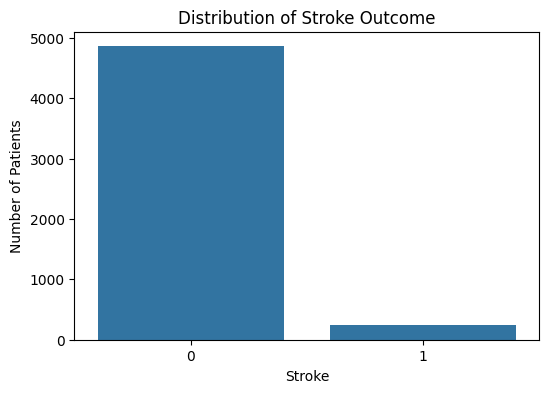

In [14]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="stroke")

plt.title("Distribution of Stroke Outcome")
plt.xlabel("Stroke")
plt.ylabel("Number of Patients")

plt.show()

Observations:

The distribution of the target variable ('stroke') reveals a significant class imbalance in the dataset. The majority class, patients without stroke (Class 0), contains 4,861 cases (95.13%), while the minority class, patients with stroke (Class 1), contains 249 cases (4.87%).

This imbalance is an important consideration during model development because machine learning algorithms may become biased toward the majority class, resulting in high overall accuracy but poor performance in identifying stroke cases. Therefore, techniques such as class balancing and evaluation metrics beyond accuracy (e.g., Precision, Recall, F1-Score, and ROC-AUC) will be considered to ensure effective stroke prediction.

###4.2 Numerical distributions

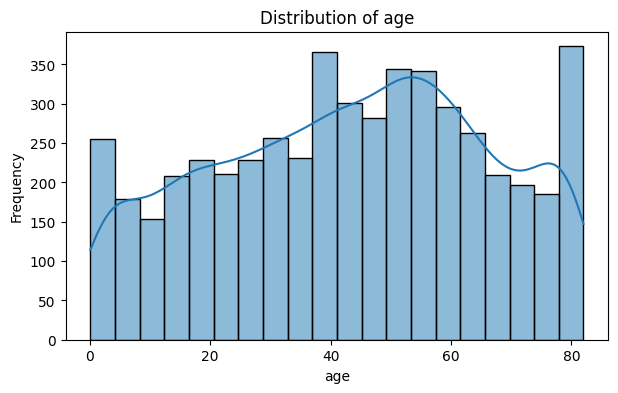

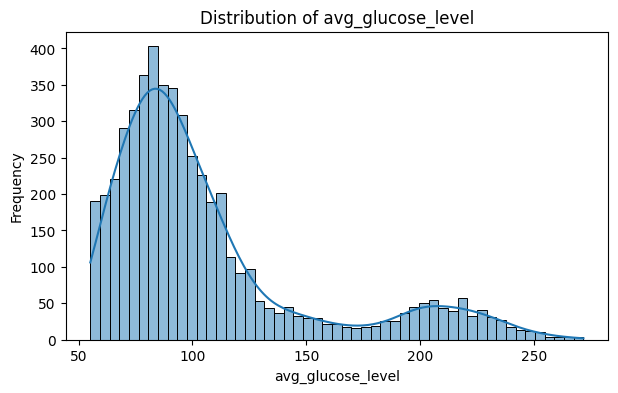

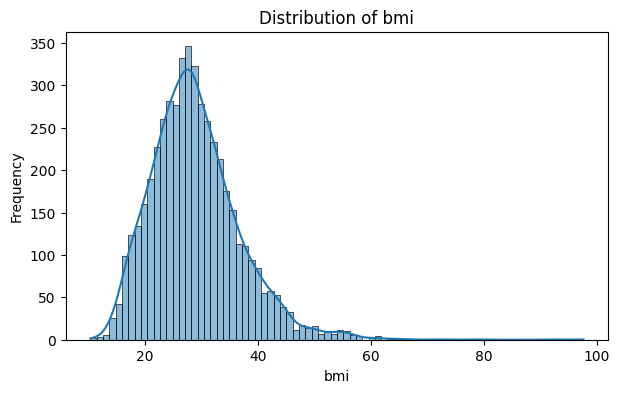

In [15]:
# Identify the numerical columns
numerical_columns = [
    "age",
    "avg_glucose_level",
    "bmi"
]

# Visualize feature distributions using histograms and KDE curves
for column in numerical_columns:

    plt.figure(figsize=(7, 4))

    sns.histplot(data=df, x=column, kde=True)

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()

Observations:

Age: The age distribution is fairly spread across the dataset, with a higher concentration of individuals between approximately 40 and 60 years old. Middle-aged and older adults appear more frequently than younger individuals.

Average Glucose Level: The distribution is right-skewed, indicating that most individuals have lower average glucose levels, while a smaller proportion have considerably higher glucose levels.

BMI: The bmi distribution is almost bell-shaped and slightly right-skewed. Most individuals fall within the healthy to overweight range, with fewer individuals having very high bmi values.

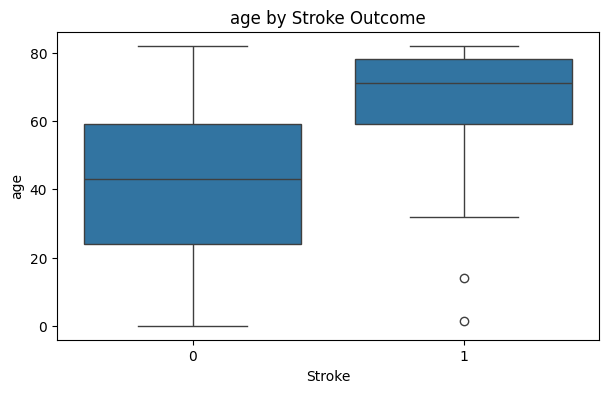

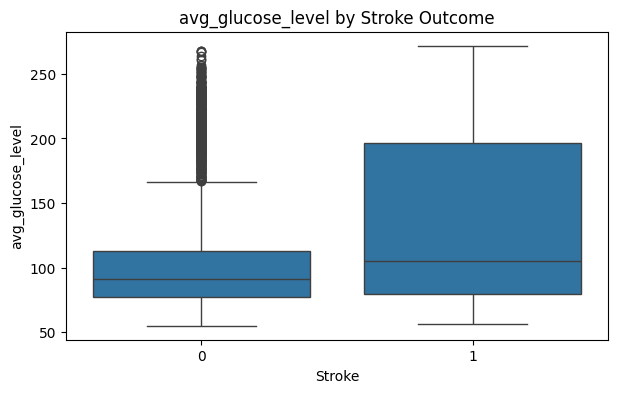

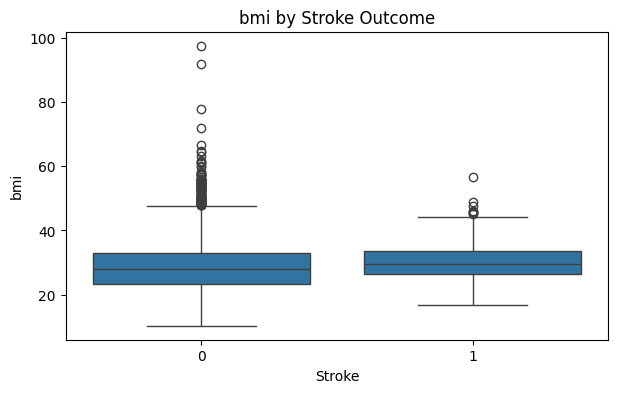

In [16]:
# Compare numerical feature distributions across stroke outcomes using boxplots
for column in numerical_columns:

    plt.figure(figsize=(7, 4))

    sns.boxplot(data=df, x="stroke", y=column)

    plt.title(f"{column} by Stroke Outcome")
    plt.xlabel("Stroke")
    plt.ylabel(column)

    plt.show()

Observations:

Age by Stroke Outcome: The box plot indicates that patients who experienced a stroke tend to be older than those who did not. The median age for the stroke group is noticeably higher, and the distribution is concentrated among older age ranges. This suggests that age is a significant factor associated with stroke occurrence.

Average Glucose Level by Stroke Outcome: The box plot shows that patients with stroke generally have higher average glucose levels than patients without stroke. The stroke group exhibits a higher median glucose level and greater variability, indicating a potential relationship between elevated glucose levels and stroke risk.

BMI by Stroke Outcome: The box plot for bmi shows substantial overlap between the stroke and non-stroke groups. Although the stroke group appears to have a slightly higher median bmi, the distributions are largely similar. This suggests that BMI alone may not be a strong predictor of stroke in this dataset. However, several outliers are present in both groups, indicating considerable variation in BMI values.

In [17]:
# Detect potential outliers using the IQR method

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n{column}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {len(outliers)}")


age
Q1: 25.00
Q3: 61.00
IQR: 36.00
Lower bound: -29.00
Upper bound: 115.00
Potential outliers: 0

avg_glucose_level
Q1: 77.25
Q3: 114.09
IQR: 36.84
Lower bound: 21.98
Upper bound: 169.36
Potential outliers: 627

bmi
Q1: 23.50
Q3: 33.10
IQR: 9.60
Lower bound: 9.10
Upper bound: 47.50
Potential outliers: 110


Findings:

Outliers were examined using the IQR method. No outliers were found in the age feature, while avg_glucose_level and bmi contained 627 and 110 potential outliers respectively. These observations were retained in the dataset because they likely represent valid medical measurements rather than data entry errors. In healthcare datasets, extreme glucose levels and BMI values may be clinically meaningful and could provide important information for stroke prediction. Removing these values could result in the loss of valuable information and potentially reduce model performance.

###4.3 Categorical variables

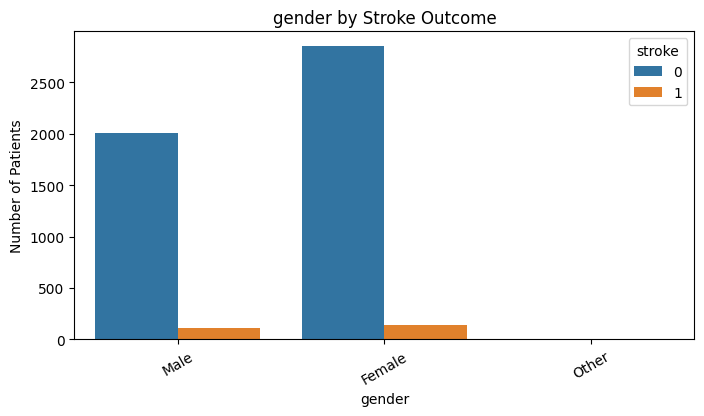

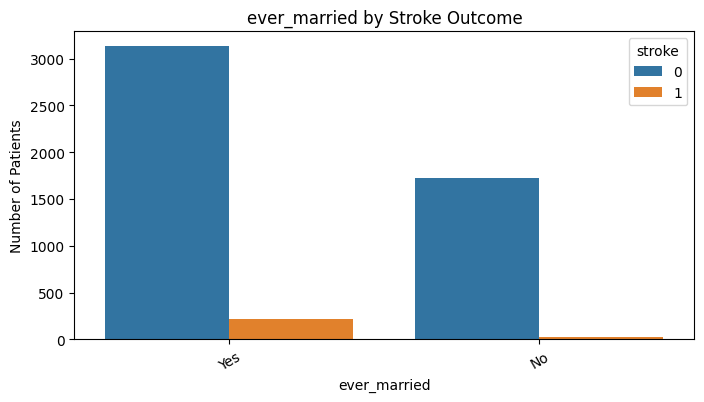

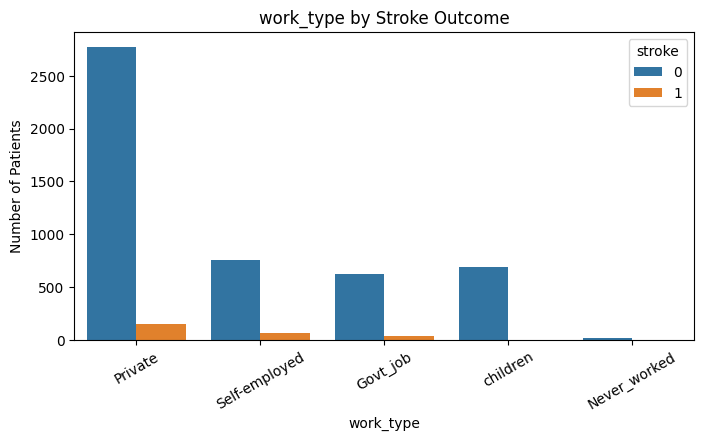

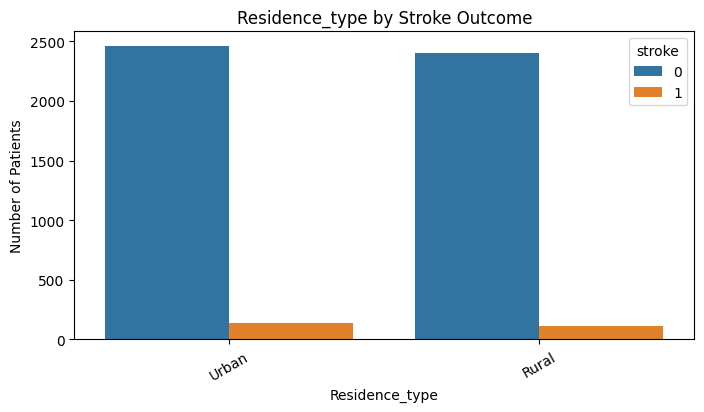

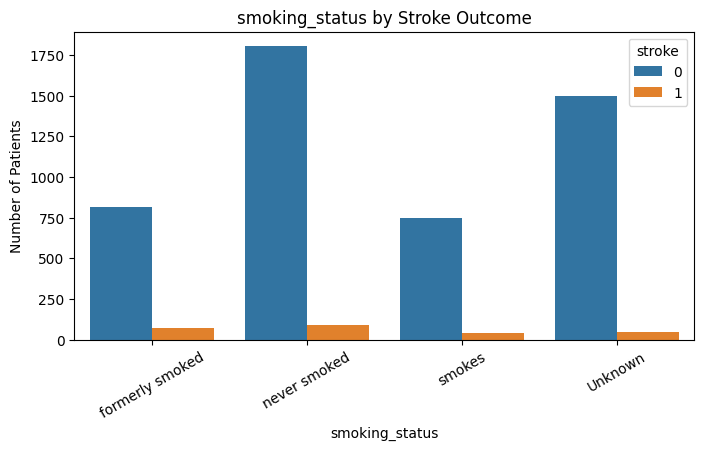

In [18]:
# Identify the categorical columns
categorical_columns = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

# Categorical Feature Analysis by Stroke Outcome
for column in categorical_columns:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=column,
        hue="stroke"
    )

    plt.title(f"{column} by Stroke Outcome")
    plt.xlabel(column)
    plt.ylabel("Number of Patients")

    plt.xticks(rotation=30)

    plt.show()

Observations:

Gender by Stroke Outcome: The dataset contains more female patients than male patients. Consequently, the absolute number of stroke cases is slightly higher among females. The "Other" gender category contains very few observations and no recorded stroke cases.

Ever Married by Stroke Outcome: Individuals who have been married exhibit a higher number of stroke cases than those who have never been married. This may be associated with age, as older individuals are more likely to be married and may also have a higher risk of stroke.

Work Type by Stroke Outcome: The highest number of stroke cases is observed among individuals working in the private sector and those who are self-employed. Government employees also show some stroke cases, while the "children" and "Never_worked" categories have very few stroke cases.

Residence Type by Stroke Outcome: Stroke cases appear to be distributed similarly between urban and rural residents. Based on the observed counts, residence type does not appear to have a strong relationship with stroke occurrence.

Smoking Status by Stroke Outcome: Former smokers and individuals who currently smoke show noticeable numbers of stroke cases. However, the "never smoked" category also records a considerable number of stroke cases due to its larger population size. Additionally, the "Unknown" category contains many individuals, which limits the ability to draw definitive conclusions regarding smoking habits and stroke risk.

###4.4 Correlation Analysis



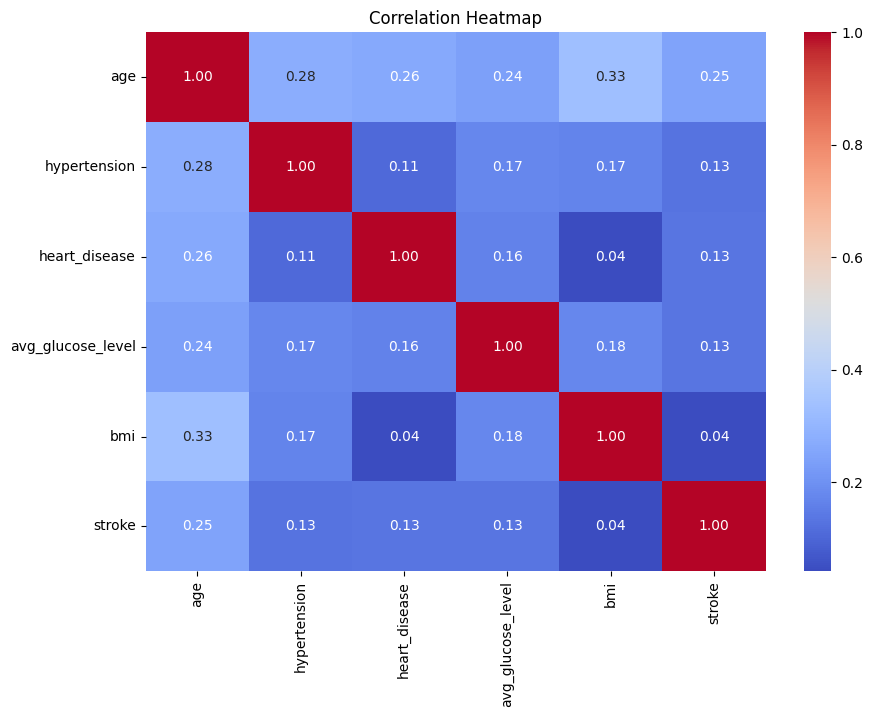

In [19]:
# Visualize correlations among numerical features using a heatmap
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Observations:

Age and Stroke: Age exhibits the strongest positive correlation with stroke (r = 0.25) among the numerical features. This finding is consistent with previous analyses, indicating that older individuals are at a higher risk of experiencing stroke.

Average Glucose Level and Stroke: Average glucose level shows a positive correlation with stroke (r = 0.13). Although the relationship is relatively weak, it suggests that individuals with higher glucose levels may have an increased likelihood of stroke.

Heart Disease and Hypertension with Stroke: Both heart disease (r = 0.13) and hypertension (r = 0.13) demonstrate positive correlations with stroke. This supports existing medical evidence that these conditions are important risk factors associated with stroke occurrence.

BMI and Stroke: BMI has a very weak positive correlation with stroke (r = 0.04). This suggests that BMI alone is not a strong linear predictor of stroke within this dataset. This observation is consistent with the earlier box plot analysis, which showed substantial overlap between the stroke and non-stroke groups.

Inter-Feature Relationships: Age is positively correlated with hypertension (r = 0.28), heart disease (r = 0.26), average glucose level (r = 0.24), and BMI (r = 0.33). These relationships are biologically plausible, as the prevalence of these health conditions tends to increase with age.

Hypertension and heart disease also show a positive correlation (r = 0.11), suggesting that these conditions may frequently co-occur. Overall, most feature pairs exhibit weak to moderate correlations, indicating limited multicollinearity among the numerical variables.


##5. Data Preprocessing

This is were we will describe all the steps taken to prepare the data before training the models.

###5.1 Feature and Target Separation

In [20]:
# Separate features and target variable
X = df.drop(columns=["stroke"])
y = df["stroke"]

The dataset was divided into predictor variables (X) and the target variable (y).

X contains all input features used to predict stroke occurrence. While y contains the target variable (stroke), where:
- 0 = No Stroke
- 1 = Stroke

This separation is necessary before training our machine learning models.

###5.2 Train-Test Split

In [21]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


The dataset was split into training and testing sets using an 80:20 ratio.

- 80% of the data was used for training the model
- 20% of the data was reserved for evaluating model performance

The parameter 'stratify=y' was applied to preserve the original class distribution of the target variable in both the training and testing sets. This is important because the dataset is imbalanced, with significantly fewer stroke cases than non-stroke cases. Finally, a 'random_state' of 42 was used to ensure reproducibility of the results.

###5.3 Numerical Feature Scaling

In [22]:
numerical_features = [
    "age",
    "avg_glucose_level",
    "bmi"
]

These features are measured on different scales and ranges. Feature scaling is applied to ensure that no single feature disproportionately influences the machine learning model due to its magnitude. Scaling improves the performance of distance-based and gradient-based algorithms and helps achieve more stable model training. The features 'age', 'avg_glucose_level', and 'bmi' were identified as continuous numerical variables and were therefore included in the scaling process.

###5.4 Categorical Encoding

In [23]:
categorical_features = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

Since machine learning algorithms require numerical input, these categorical variables must be converted into a numerical format before model training. Encoding preserves the information contained in these variables while making them suitable for use in predictive models. The identified categorical features represent demographic, lifestyle, and socioeconomic characteristics that may contribute to stroke risk and were therefore included in the encoding process.

###5.5 Class Imbalance

In [24]:
# Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

Missing values in the bmi feature were imputed using the median. The imputation parameters were learned from the training data and subsequently applied to both the training and testing datasets to prevent data leakage. The median was selected because it is less sensitive to outliers than the mean, making it a more robust measure for handling skewed distributions.

Additionally, we used StandardScaler for numerical features to bring them to a similar scale (mean 0, standard deviation 1). This is important because many machine learning algorithms perform better or converge faster when features have similar ranges, preventing features with larger values from dominating the model.

While OneHotEncoder is used to covert categorical features into a numerical format that our machine learning model can understand. It creates new binary columns for each category, avoiding the incorrect assumption of order that might arise from simple numerical labeling and preventing multicollinearity with drop='first'.

##6. Model Development

This is the stage where we will build and train the machine learning models.

###6.1 Logistic Regression

In [25]:
# Create a Logistic Regression model with preprocessing and class imbalance handling
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        )
    ]
)

Logistic Regression was selected as a baseline classification model for our task because it is well suited for binary classification problems, where the target variable has two possible outcomes (stroke or no stroke).

The model provides interpretable results by estimating the relationship between predictor variables and the probability of stroke occurrence. This interpretability makes it useful for understanding the influence of risk factors on stroke prediction.

Additionally, Logistic Regression serves as a strong baseline model against which the performance of more complex machine learning algorithms can be compared. To address the class imbalance present in the dataset, the model was configured with class_weight='balanced', which automatically assigns higher importance to the minority class (stroke cases) during training.

The parameter max_iter=1000 was also specified to ensure convergence during the optimization process.

In [26]:
# Train it
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['gender','age','hypertension',...,'avg_glucose_level','bmi', 'smoking_status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthr

Observations:

The pipeline diagram confirms that the preprocessing steps are applied before model training.

- Numerical features undergo median imputation followed by standardization
- Categorical features are encoded using One-Hot Encoding
- The transformed features are then passed to the Logistic Regression classifier

This workflow ensures that all data preprocessing operations are consistently applied during both training and prediction.

###Save the Trained Model for Deployment

This stage was carried out after model evaluation, since Logistic Regression emerged as the most effective model for this dataset.

In [27]:
import joblib

# Save the trained Logistic Regression pipeline
# including its preprocessing steps, to a Joblib file.
# This allows the trained model to be loaded by the Streamlit
# application without retraining it for every prediction.

joblib.dump(logistic_model, "/content/stroke_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [28]:
# Download the model file
from google.colab import files

files.download("/content/stroke_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
# Generating predictions
y_pred_lr = logistic_model.predict(X_test)

After training the Logistic Regression model, predictions were generated using the test dataset (X_test).

The predict() function applies the trained preprocessing pipeline and Logistic Regression classifier to unseen data and returns the predicted class labels:

- 0 = No Stroke
- 1 = Stroke

The predicted results were stored in the variable y_pred_lr and were subsequently used to evaluate the model's performance using classification metrics such as Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

##6.2 Random Forest

In [30]:
# Create a Random Forest classifier with data preprocessing and class imbalance handling
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

Random Forest was selected as the second classification algorithm because it is an ensemble learning method that combines multiple decision trees to improve predictive performance and reduce overfitting. It can effectively capture complex, non-linear relationships within the data and provides insights into feature importance, which can help identify factors associated with stroke occurrence.

The model was configured with 'n_estimators=300', meaning that 300 decision trees were built and combined to produce the final prediction. Increasing the number of trees generally improves model stability and predictive accuracy.

To address the class imbalance present in the dataset, the parameter 'class_weight='balanced'' was applied. This automatically assigns higher weights to the minority class (stroke cases) and lower weights to the majority class (non-stroke cases), helping the model pay greater attention to stroke instances during training and improving its ability to detect individuals at risk of stroke.

A 'random_state' of 42 was used to ensure reproducibility of the results.

In [31]:
# Train it
random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['gender','age','hypertension',...,'avg_glucose_level','bmi', 'smoking_status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthr

Observations:

Similar to the logistic regression pipeline, this pipeline diagram also confirms that the preprocessing steps are applied before model training.

- Numerical features undergo median imputation followed by standardization
- Categorical features are encoded using One-Hot Encoding
- The transformed features are then passed to the Random Forest classifier

This workflow ensures that all data preprocessing operations are consistently applied during both training and prediction. Additionally, the Random Forest classifier can capture complex, non-linear relationships between features, making it suitable for identifying patterns associated with stroke risk.

In [32]:
# Generating predictions
y_pred_rf = random_forest_model.predict(X_test)

Following the training phase, the Random Forest model was applied to the test dataset (X_test) to generate stroke predictions.

The predict() method processes the unseen test data through the complete preprocessing pipeline and then uses the trained Random Forest classifier to assign a class label for each observation:

- 0 = No Stroke
- 1 = Stroke

The predicted labels were stored in the variable y_pred_rf. These predictions were then used to assess the effectiveness of the Random Forest model through various evaluation metrics, including Accuracy, Precision, Recall, F1-Score, and ROC-AUC, allowing its performance to be compared with the Logistic Regression model.

###7. Model Evaluation

This is where the performance of the trained machine learning models is assessed using relevant evaluation metrics to determine their effectiveness in predicting stroke risk.

###7.1 Classification Metrics

In [33]:
# Evaluate model performance using standard classification metrics
def evaluate_model(model_name, y_true, y_pred):

    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print("Accuracy:",
          accuracy_score(y_true, y_pred))

    print(
        "Precision:",
        precision_score(
            y_true,
            y_pred,
            zero_division=0
        )
    )

    print(
        "Recall:",
        recall_score(
            y_true,
            y_pred,
            zero_division=0
        )
    )

    print(
        "F1 Score:",
        f1_score(
            y_true,
            y_pred,
            zero_division=0
        )
    )

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            zero_division=0
        )
    )

To evaluate the performance of the trained classification models, a reusable evaluation function was created. The function compares the model's predicted labels (y_pred) with the actual test labels (y_true) and calculates several performance metrics.

The evaluation includes:

Accuracy: Measures the overall proportion of correctly classified instances

Precision: Measures the proportion of predicted stroke cases that were correctly identified

Recall: Measures the proportion of actual stroke cases that were successfully detected by the model

F1-Score: Provides a balanced measure of Precision and Recall, making it particularly useful for imbalanced datasets

The parameter zero_division=0 was included to prevent errors in situations where a class receives no predicted instances.

This evaluation framework provides a comprehensive assessment of model performance and enables objective comparison between the Logistic Regression and Random Forest classifiers.

In [34]:
evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_lr
)

Logistic Regression
Accuracy: 0.7446183953033269
Precision: 0.13494809688581316
Recall: 0.78
F1 Score: 0.23008849557522124

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.74      0.85       972
           1       0.13      0.78      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.76      0.54      1022
weighted avg       0.94      0.74      0.82      1022



The classification report shows that the model achieved an accuracy of 74.46%, indicating that approximately three-quarters of the test instances were classified correctly. However, accuracy alone is not sufficient due to the class imbalance in the dataset.

For the stroke class (Class 1), the model achieved a recall of 78%, meaning it successfully identified 78% of actual stroke cases. This is important in a healthcare context because failing to detect a patient at risk of stroke can have serious consequences.

However, the precision of 13.49% indicates that many patients predicted as having a stroke were actually non-stroke cases. As a result, the model produced a relatively high number of false positives. This is also reflected in the F1-score of 0.23, which suggests that while the model is effective at identifying stroke cases, its overall balance between precision and recall remains limited.

Overall, the Logistic Regression model demonstrates strong sensitivity to stroke cases but struggles with precision. This indicates that the model prioritizes detecting potential stroke patients at the cost of generating more false alarms, which may be acceptable in medical screening scenarios where missing a stroke case is more critical than conducting additional follow-up assessments.

In [35]:
evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf
)

Random Forest
Accuracy: 0.9227005870841487
Precision: 0.08571428571428572
Recall: 0.06
F1 Score: 0.07058823529411765

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       972
           1       0.09      0.06      0.07        50

    accuracy                           0.92      1022
   macro avg       0.52      0.51      0.52      1022
weighted avg       0.91      0.92      0.92      1022



Here the model achieved an accuracy of 94.81%, which appears to be very high. However, accuracy alone can be misleading when evaluating imbalanced datasets. The majority of patients in the dataset belong to the non-stroke class, allowing the model to achieve high accuracy by primarily predicting the majority class.

For the non-stroke class (Class 0), the model achieved a precision of 95%, recall of 100%, and an F1-score of 97%, indicating excellent performance in identifying patients without stroke.

However, for the stroke class (Class 1), the model achieved a precision of 0%, recall of 0%, and an F1-score of 0%. This indicates that the model failed to correctly identify any stroke cases in the test dataset. In other words, all actual stroke cases were classified as non-stroke patients.

Although the model produced a high overall accuracy, it was ineffective for the primary objective of this study, which is to identify individuals at risk of stroke. The results suggest that the Random Forest model was heavily influenced by the majority class despite the use of class_weight='balanced'.

Overall, the Random Forest model demonstrated excellent performance for the non-stroke class but failed to detect stroke cases. Therefore, based on recall and F1-score for the minority class, Logistic Regression performed better as a stroke prediction model because it was able to identify a substantial proportion of stroke cases.

###7.2 Confusion Matrices

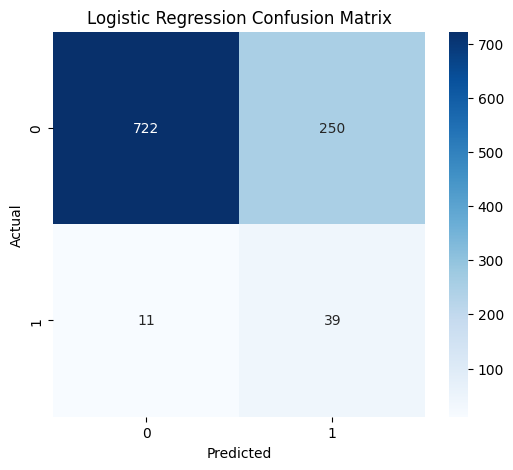

In [36]:
# Generate and visualize the confusion matrix for the Logistic Regression model
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Observations:

The confusion matrix successfully provided a detailed breakdown of the Logistic Regression model's predictions.

- True Negatives (TN): The model correctly identified 722 patients who did not experience a stroke

- False Positives (FP): The model incorrectly predicted 250 patients as having a stroke when they did not

- False Negatives (FN): The model failed to identify 11 actual stroke cases and incorrectly classified them as non-stroke

- True Positives (TP): The model correctly identified 39 patients who experienced a stroke

The confusion matrix shows that the model successfully detected most stroke cases, correctly identifying 39 out of 50 actual stroke patients. This is reflected in the high recall score of 78%. However, the model also generated a relatively high number of false positives (250), indicating that many non-stroke patients were incorrectly classified as being at risk of stroke.

Overall, the Logistic Regression model prioritizes identifying stroke cases, resulting in a high recall but lower precision. In a healthcare setting, this behavior may be acceptable because missing a stroke case could be more critical than conducting additional medical evaluations for patients who are incorrectly flagged as high risk.

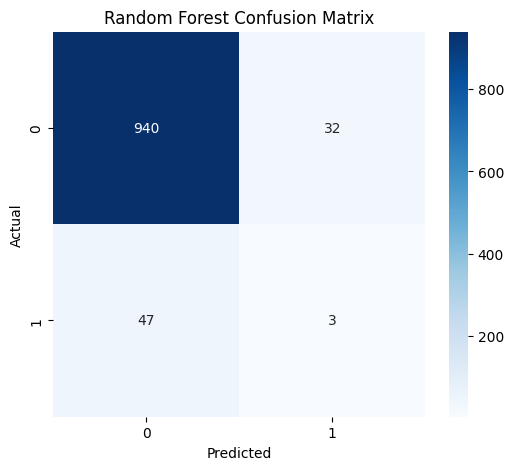

In [37]:
# Generate and visualize the confusion matrix for the Random Forest model
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Observations:

- The model correctly classified 969 non-stroke cases (True Negatives)
- The model incorrectly classified 3 non-stroke cases as stroke (False Positives)
- The model incorrectly classified 50 stroke cases as non-stroke (False Negatives)
- The model correctly identified 0 stroke cases (True Positives)

These results indicate that the Random Forest model was highly effective at identifying patients without stroke but failed to detect any actual stroke cases in the test set. This behavior is likely influenced by the significant class imbalance present in the dataset, where non-stroke cases greatly outnumber stroke cases.

Although the model may achieve a high overall accuracy due to correctly classifying most non-stroke patients, its Recall for the stroke class is 0%, meaning that none of the actual stroke cases were detected. In a healthcare application, this is a critical limitation because undetected stroke cases may prevent timely intervention and treatment.

Therefore, metrics such as Recall, F1-Score, and ROC-AUC should be considered alongside Accuracy when evaluating the effectiveness of the model.

### 7.3 ROC-AUC Evaluation

In [38]:
# Calculate and compare ROC-AUC scores for the Logistic Regression and Random Forest models
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

auc_lr = roc_auc_score(y_test, y_prob_lr)

auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Logistic Regression ROC-AUC:", auc_lr)
print("Random Forest ROC-AUC:", auc_rf)

Logistic Regression ROC-AUC: 0.8426954732510288
Random Forest ROC-AUC: 0.7669032921810699


To further assess the ability of the models to distinguish between stroke and non-stroke cases, the Receiver Operating Characteristic Area Under the Curve (ROC-AUC) metric was calculated.

Instead of using the predicted class labels, the predict_proba() function was used to obtain the probability of each patient belonging to the stroke class (Class 1). These probability scores provide more detailed information about the model's confidence in its predictions and are required for ROC-AUC analysis.

From the ROC-AUC scores obtained, the Logistic Regression model achieved a higher ROC-AUC score (0.843) than the Random Forest model (0.770). This indicates that Logistic Regression was more effective at distinguishing between patients with stroke and those without stroke across different classification thresholds.

Both models achieved ROC-AUC scores above 0.70, suggesting that they possess reasonable discriminative power. However, the superior ROC-AUC score of the Logistic Regression model demonstrates a stronger ability to rank stroke cases higher than non-stroke cases.

Considering the class imbalance present in the dataset, ROC-AUC provides a more reliable measure of model performance than accuracy alone. Based on the ROC-AUC results, Logistic Regression demonstrated better overall classification performance and was more successful at identifying patterns associated with stroke risk.

### 7.4 ROC Curve Analysis

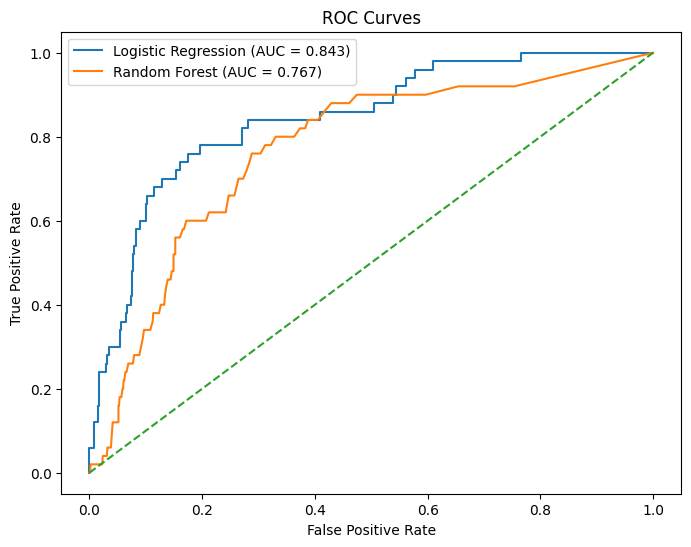

In [39]:
# ROC Curve Comparison
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {auc_lr:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

The Receiver Operating Characteristic (ROC) curve was plotted to compare the classification performance of the Logistic Regression and Random Forest models across different decision thresholds.

The ROC curve illustrates the trade-off between:

- True Positive Rate (Recall), which measures the proportion of actual stroke cases correctly identified

- False Positive Rate, which measures the proportion of non-stroke cases incorrectly classified as stroke

The diagonal reference line represents the performance of a random classifier. Models with curves that are closer to the top-left corner demonstrate better discriminative ability.

Observations:

The Logistic Regression model achieved an ROC-AUC score of 0.843, indicating strong capability in distinguishing between stroke and non-stroke cases. While the Random Forest model achieved an ROC-AUC score of 0.770, demonstrating acceptable discriminative performance but lower effectiveness compared to Logistic Regression. Both ROC curves lie above the diagonal baseline, indicating that both models perform better than random guessing. However, the Logistic Regression curve remains above the Random Forest curve for most threshold values, suggesting superior classification performance across a wide range of decision thresholds.

Based on the ROC curve analysis, the Logistic Regression model outperformed the Random Forest model in distinguishing between stroke and non-stroke patients. The higher ROC-AUC value indicates that Logistic Regression provides better overall predictive performance and may be more suitable for the stroke prediction task in this dataset.

### 7.5 Model Performance Comparison

In [40]:
# Create a summary table to compare model performance metrics
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],

    "ROC-AUC": [
        auc_lr,
        auc_rf
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.744618,0.134948,0.78,0.230088,0.842695
1,Random Forest,0.922701,0.085714,0.06,0.070588,0.766903


To identify the most suitable model for stroke prediction, the performance of Logistic Regression and Random Forest was compared using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

Observations:

- The Random Forest model achieved the highest accuracy (94.81%). However, it failed to correctly identify any stroke cases, resulting in a Precision, Recall, and F1-Score of 0.00.

- The Logistic Regression model achieved a lower accuracy (74.46%) but demonstrated a substantially better ability to detect stroke cases, achieving a Recall of 0.78.

- The F1-Score of Logistic Regression (0.23) indicates a better balance between Precision and Recall compared to Random Forest.

- Logistic Regression also achieved a higher ROC-AUC score (0.843) than Random Forest (0.770), indicating stronger overall discrimination between stroke and non-stroke cases.

- The high accuracy of Random Forest is misleading due to the significant class imbalance in the dataset, as the model primarily predicted the majority class (non-stroke).

Although Random Forest achieved a higher overall accuracy, it was ineffective at identifying patients with stroke. In contrast, Logistic Regression successfully detected a large proportion of stroke cases and achieved superior Recall, F1-Score, and ROC-AUC values.

Since the primary objective of this project is to identify individuals at risk of stroke, correctly detecting stroke cases is more important than maximizing overall accuracy. Therefore, Logistic Regression was selected as the preferred model for stroke prediction due to its stronger ability to identify stroke patients and its better overall performance on the evaluation metrics

### 8. Model Deployment

Model deployment was the final stage of the project lifecycle, bringing together the results of data preprocessing, exploratory data analysis, model training, and performance evaluation into a practical application. After comparing the machine learning models, Logistic Regression was selected as the preferred model because of its ability to identify stroke cases, particularly its higher recall, which was an important consideration given the imbalanced nature of the dataset.

The trained Logistic Regression pipeline was saved using Joblib to preserve the fitted preprocessing steps and classification model for reuse. Streamlit was then used to develop a user-friendly interface that allows users to enter demographic, medical, and lifestyle information and obtain a model-generated prediction. This approach made it possible to demonstrate the model's functionality without requiring users to run the original Jupyter Notebook.

The deployment stage completed the project workflow by demonstrating how the selected machine learning model could be applied through a practical, accessible interface. However, the application is intended for educational and demonstration purposes only. Its predictions should not be considered medical diagnoses or used to guide clinical decisions. Further testing, independent validation, and evaluation by qualified healthcare professionals would be required before the model could be considered for real-world clinical use.

### 9.1 Challenges Encountered

The primary challenge was severe class imbalance, with stroke cases representing less than 5% of all observations.

Additional challenges included:

- Handling missing BMI values
- Preventing data leakage
- Selecting appropriate evaluation metrics
- Interpreting conflicting performance measures

The Random Forest model's inability to detect stroke cases despite class balancing further highlighted the difficulties associated with imbalanced healthcare data.


### 9.2 Lessons Learned

Several important lessons emerged:

1. Data preprocessing significantly affects model performance
2. Accuracy alone cannot adequately evaluate imbalanced datasets
3. Recall and F1-score are more meaningful for healthcare applications
4. Different algorithms respond differently to class imbalance
5. Model evaluation should align with real-world objectives

Most importantly, maximizing stroke detection is often more valuable than maximizing overall accuracy.

## 10. Conclusion

This study developed and evaluated machine learning models for predicting stroke risk using demographic and health-related factors. Exploratory Data Analysis revealed that age, average glucose level, hypertension, and heart disease were important factors associated with stroke occurrence. Among the evaluated models, Logistic Regression achieved the best overall performance, with an ROC-AUC score of 0.843 and a Recall of 78%, demonstrating a strong ability to identify stroke cases despite the class imbalance present in the dataset.

The findings suggest that machine learning techniques can effectively support stroke prevention efforts by identifying individuals at higher risk of stroke, thereby enabling earlier intervention, monitoring, and healthcare decision-making.

## 11. References

### **Dataset**

Fedesoriano (2021). *Stroke Prediction Dataset*. Kaggle. https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset


### **Machine Learning Documentation**

scikit-learn developers (2026). *LogisticRegression*. scikit-learn documentation. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

scikit-learn developers (2026). *Metrics and scoring: Quantifying the quality of predictions*. scikit-learn documentation. https://scikit-learn.org/stable/modules/model_evaluation.html


### **Research Papers/Articles**

Melnykova, N., Patereha, Y., Skopivskyi, S., Farion, M., Fedushko, S., et al. (2025). *Machine learning for stroke prediction using imbalanced data*. Scientific Reports, 15, 33773. https://www.nature.com/articles/s41598-025-01855-w

Li, X., et al. (2020). *Stroke Prediction with Machine Learning Methods among Older Chinese*. *International Journal of Environmental Research and Public Health*. https://pmc.ncbi.nlm.nih.gov/articles/PMC7142983/


### **Code Resources**

scikit-learn developers (2026). *scikit-learn: Machine learning in Python*. GitHub. https://github.com/scikit-learn/scikit-learn

scikit-learn developers. (2026). *Classification metrics*. scikit-learn documentation. https://scikit-learn.org/stable/modules/model_evaluation.html

Kaggle. (n.d.). *Stroke Prediction Dataset: Code and notebooks*. Kaggle. https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset


### **AI Assistance**

OpenAI (2026). *ChatGPT* [Large language model]. Used for code assistance and explanation of machine-learning concepts. Generated code and suggestions were reviewed, understood, tested, modified, and adapted by the project team.

Google (2026). Gemini in Google Colab [AI coding assistant]. Used for debugging, code explanations, and support with developing and testing the machine-learning workflow in Google Colab.
